### Install packages

In [ ]:
%pip install -q googlemaps statsmodels scikit-learn nltk

  Preparing metadata (setup.py) ... done


### Imports and settings

In [ ]:
import os, re, json, pathlib, platform, warnings
from datetime import date, time, datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")

SURVEY_CSV = "survey.csv"
QUERY_DATE = date(2026, 11, 24)
TZ = timezone(timedelta(hours=-4))
ARRIVAL = time(8, 0)
OFFSETS = list(range(0, 106, 15))
TRAFFIC_MODEL = "best_guess"
PCT = 90
RATE = 0.50
WEEKS = 4.33
OPEN_BIN = 97
N_BOOT = 5000
SEED = 42

OFFICES = {"Chaguanas": (10.5169, -61.4111), "San Fernando": (10.2820, -61.4678), "Arima": (10.6383, -61.2853)}
POS = {"POS": (10.6667, -61.5167)}
BOX = {"lat": (10.0, 11.0), "lng": (-62.0, -60.5)}

OUT_DIR, RAW_DIR, CACHE_DIR = pathlib.Path("outputs"), pathlib.Path("raw_api"), pathlib.Path("cache")
for d in (OUT_DIR, RAW_DIR, CACHE_DIR):
    d.mkdir(exist_ok=True)

gm = None

def client():
    global gm
    if gm is None:
        import googlemaps
        from getpass import getpass
        gm = googlemaps.Client(key=os.environ.get("GOOGLE_MAPS_API_KEY") or getpass("Google Maps API key: "))
    return gm

### Load and clean the survey

In [ ]:
df = pd.read_csv(SURVEY_CSV)
df["RespondentID"] = df.index
df = df.drop(columns=[c for c in df.columns if "timestamp" in c.lower()])

def col(key):
    return next(c for c in df.columns if key.lower() in c.lower())

df = df.rename(columns={
    col("Which area"): "HomeLocation", col("How do you commute"): "Mode", col("How much do you pay"): "CostRaw",
    col("one-way commute time"): "Bin", col("How many days"): "DaysRaw", col("[Stress]"): "Stress",
    col("[Family Time]"): "FamilyTime", col("[Job Satisfaction]"): "JobSatisfaction",
    col("[Physical Health]"): "PhysicalHealth", col("relocate"): "Relocate", col("Which company"): "Work"})

df["HomeLocation"] = df["HomeLocation"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
first = {}
for a in df["HomeLocation"]:
    first.setdefault(a.lower(), a)
df["HomeLocation"] = df["HomeLocation"].str.lower().map(first)

mid = {"less than 15 minutes": 10, "15-29 minutes": 22, "30-44 minutes": 37, "45-59 minutes": 52,
       "60-74 minutes": 67, "75-89 minutes": 82, "90+ minutes": OPEN_BIN}
df["Bin"] = df["Bin"].astype(str).str.replace("\u2013", "-").str.replace("\u2014", "-").str.strip().str.lower()
df["CommuteMins"] = df["Bin"].map(mid)

def days(v):
    s = str(v).lower()
    if "less than 1" in s:
        return 0.5
    m = re.search(r"\d+", s)
    return float(m.group()) if m else np.nan

df["CommuteDays"] = df["DaysRaw"].map(days)
df["CommuteDays"] = df["CommuteDays"].fillna(df["CommuteDays"].median())

def cost(v):
    if pd.isna(v):
        return np.nan
    nums = re.findall(r"\d+\.\d+|\d+", str(v).replace(",", ""))
    return float(np.mean([float(x) for x in nums])) if nums else np.nan

df["CostReported"] = df["CostRaw"].map(cost)
pub = df["Mode"].astype(str).str.contains("Public", case=False)
pri = df["Mode"].astype(str).str.contains("Private", case=False)
rep = df["CostReported"].notna()
fill = np.select([pub, pri], [df.loc[pub & rep, "CostReported"].mean(), df.loc[pri & rep, "CostReported"].mean()],
                 df.loc[rep, "CostReported"].mean())
df["Cost_Imputed"] = ~rep
df["TravelCost"] = df["CostReported"].fillna(pd.Series(fill, index=df.index))
df["IsDriver"] = pri

mode = df["Mode"].astype(str).str.strip()
df["ModeClass"] = np.select([mode.eq("Private vehicle"), mode.eq("Public transportation")],
                            ["Private vehicle only", "Public transport only"], "Mixed / other")

for c in ["Stress", "FamilyTime", "JobSatisfaction", "PhysicalHealth"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

n = len(df)

### Summarise commute time and cost

In [ ]:
print("n =", n, "| home areas =", df.HomeLocation.nunique())
display(df[["CommuteMins", "TravelCost"]].agg(["mean", "median"]).round(2))
print("max monthly cost:", df.TravelCost.max())
print("90+ minutes:", (df.Bin == "90+ minutes").sum(), "| under 15 minutes:", (df.Bin == "less than 15 minutes").sum())
display(df.groupby("ModeClass")["CostReported"].agg(["size", "count", "mean"]).round(2))

n = 89 | home areas = 45


,CommuteMins,TravelCost
mean,64.2,850.84
median,67.0,800.00


max monthly cost: 2650.0
90+ minutes: 20 | under 15 minutes: 2


,size,count,mean
ModeClass,,,
Mixed / other,18,12,754.00
Private vehicle only,47,45,935.56
Public transport only,24,17,762.35


### Build the sample characteristics table

In [ ]:
tab1 = pd.concat([df.ModeClass.value_counts(), pd.Series({
    "Cost imputed": df.Cost_Imputed.sum(),
    "Commute five days per week": (df.CommuteDays == 5).sum(),
    "Commute 90+ minutes one way": (df.Bin == "90+ minutes").sum(),
    "Gave a relocation answer": df.Relocate.notna().sum(),
    "No company given": df.Work.isna().sum()})]).to_frame("n")
tab1["%"] = (tab1["n"] / n * 100).round(1)
display(tab1)

,n,%
Private vehicle only,47,52.8
Public transport only,24,27.0
Mixed / other,18,20.2
Cost imputed,15,16.9
Commute five days per week,59,66.3
Commute 90+ minutes one way,20,22.5
Gave a relocation answer,83,93.3
No company given,17,19.1


### Plot the commute-time distribution

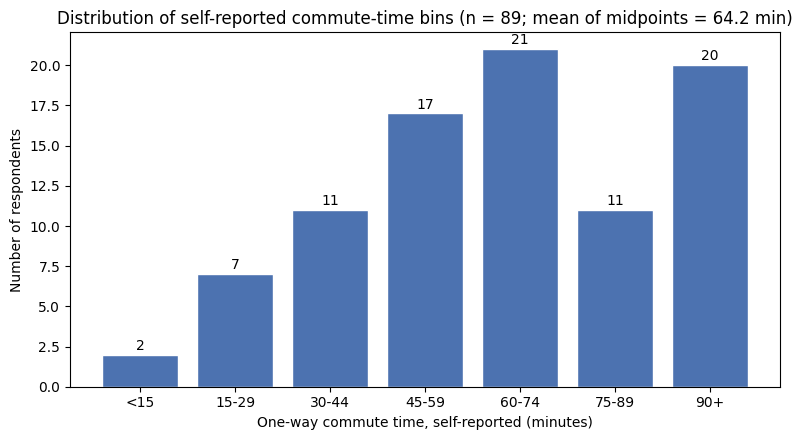

In [ ]:
counts = df["Bin"].value_counts().reindex(list(mid)).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(7), counts.values, color="#4C72B0", edgecolor="white")
ax.set_xticks(range(7))
ax.set_xticklabels(["<15", "15-29", "30-44", "45-59", "60-74", "75-89", "90+"])
ax.set_xlabel("One-way commute time, self-reported (minutes)")
ax.set_ylabel("Number of respondents")
ax.set_title(f"Distribution of self-reported commute-time bins (n = {n}; mean of midpoints = {df.CommuteMins.mean():.1f} min)")
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.3, str(v), ha="center")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig1_commute_bins.png", dpi=200)
plt.show()

### Test commute time against well-being

In [ ]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

labels = {"Stress": "Stress", "FamilyTime": "Family time", "PhysicalHealth": "Physical health", "JobSatisfaction": "Job satisfaction"}
rng = np.random.default_rng(SEED)
x = df["CommuteMins"].values
rows = []
for c, lab in labels.items():
    y = df[c].values
    rho, p = stats.spearmanr(x, y)
    tau = stats.kendalltau(x, y, variant="b")[0]
    boot = []
    for _ in range(N_BOOT):
        i = rng.integers(0, n, n)
        boot.append(stats.spearmanr(x[i], y[i])[0])
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    rows.append({"Variable": lab, "rho": rho, "CI_low": lo, "CI_high": hi, "p": p, "tau_b": tau})
tab2 = pd.DataFrame(rows)

order = np.argsort(tab2["p"].values)
adj, run = np.empty(len(tab2)), 0.0
for r, i in enumerate(order):
    run = max(run, (len(tab2) - r) * tab2["p"].values[i])
    adj[i] = min(1.0, run)
tab2["p_Holm"] = adj

X = pd.DataFrame({"Commute_per_10min": df["CommuteMins"] / 10, "Driver": df["IsDriver"].astype(float), "Days": df["CommuteDays"]})
ors = []
for c in labels:
    y = df[c].astype(pd.CategoricalDtype([1, 2, 3, 4, 5], ordered=True))
    res = OrderedModel(y, X, distr="logit").fit(method="bfgs", disp=False)
    b, ci = res.params["Commute_per_10min"], res.conf_int().loc["Commute_per_10min"]
    ors.append({"OR": np.exp(b), "OR_low": np.exp(ci.iloc[0]), "OR_high": np.exp(ci.iloc[1]), "p_OR": res.pvalues["Commute_per_10min"]})
tab2 = pd.concat([tab2, pd.DataFrame(ors)], axis=1)
display(tab2.round(4))

,Variable,rho,CI_low,CI_high,p,tau_b,p_Holm,OR,OR_low,OR_high,p_OR
0,Stress,0.5745,0.3915,0.7171,0.0,0.4817,0.0,1.8701,1.5285,2.2881,0.0
1,Family time,0.6159,0.4404,0.7552,0.0,0.5259,0.0,1.9535,1.5823,2.4117,0.0
2,Physical health,0.4373,0.2234,0.6107,0.0,0.3586,0.0,1.4886,1.2500,1.7728,0.0
3,Job satisfaction,0.4264,0.2171,0.6237,0.0,0.3532,0.0,1.5379,1.2837,1.8423,0.0


### Code the relocation answers

In [ ]:
STANCE = {
    'no because pos is closer to me': 'Oppose / no need',
    'yes, due to difficulties with parking in pos ': 'Support',
    'yes. i would live better and produce higher q': 'Support',
    'yes': 'Support',
    'yes computing to pos is taking a toll on my b': 'Support',
    'yes i would relocate to an office closer to h': 'Support',
    'yes because fatigue management is not being c': 'Support',
    'yes, to reduce my commute time': 'Support',
    'yes. save time spent commuting. have more per': 'Support',
    'yes - to reduce time spent in traffic and cos': 'Support',
    'yes, easier to get to and from the office.': 'Support',
    'yes. will save me atleast 4 hours a day': 'Support',
    'yes i would, to facilitate improved sleep sch': 'Support',
    'i would relocate as it would save time in com': 'Support',
    'yes i would would be a lot less time to get t': 'Support',
    'yes....more home life balance': 'Support',
    'ideally if i could i would - the chaguanas ro': 'Conditional / hybrid',
    'yes to reduce commute time': 'Support',
    'yes, to cut down on travel time which would r': 'Support',
    'yes, because it would free up my time for oth': 'Support',
    'yes, i have relocated to another job because ': 'Support',
    'yes. commute time would be shorter so i would': 'Support',
    'yes. and i might even do it for a $1000 pay c': 'Support',
    'yes because it will give me more time to focu': 'Support',
    "i don't mind working in pos 2 days a week and": 'Conditional / hybrid',
    'yes as it would reduce my commute time and gi': 'Support',
    'yes, to reduce wasting time, effort and energ': 'Support',
    'yes i would relocate, this would allow me to ': 'Support',
    'yes. less commute needed': 'Support',
    'i would if that were an option, because then ': 'Support',
    'chaguanas as it would save close to 3 hours c': 'Support (implicit)',
    'yes because the traffic situation is terrible': 'Support',
    'yes definitely, offices need to become more d': 'Support',
    'yes, this would give me back around 5 hours o': 'Support',
    'yes, more time for myself': 'Support',
    'finances, time to spend with children as it r': 'Support (implicit)',
    'i work close to home.': 'Oppose / no need',
    'to arima yes where the commute is less and i ': 'Support',
    'yes as commute takes up most of my time': 'Support',
    'no. in my current circumstance, the office is': 'Oppose / no need',
    'transportation and distance': 'Support (implicit)',
    'no, because i have flexibility in my work day': 'Oppose / no need',
    'no i would not relocate to office closer to h': 'Oppose / no need',
    'no, i prefer my own home. no sense in relocat': 'Oppose / no need',
    'i would relocate; it saves time and money.': 'Support',
    'no because i like where i live': 'Oppose / no need',
    'no, less networking opportunities based on ho': 'Oppose / no need',
    'no. i prefer to work in pos.': 'Oppose / no need',
    'yes. save me time': 'Support',
    "no. it's close enough.": 'Oppose / no need',
    'barataria is close enough to pos for it not t': 'Oppose / no need',
    'yes. commute will be less time, less traffic': 'Support',
    'yes. less commute time and less money.': 'Support',
    'shorter commute time.': 'Support (implicit)',
    'yes in a heartbeat': 'Support',
    'yes i will as it will provide me opportunitie': 'Support',
    'i am already close to work. if an opportunity': 'Oppose / no need',
    'yes. more sleep, less commute time, reach hom': 'Support',
    'yes. i would so that i can get enough sleep, ': 'Support',
    'no. i prefer pos as it is close to essential ': 'Oppose / no need',
    'yes, where i live requires a lot of walking a': 'Support',
    'i already live and work in the north west.': 'Oppose / no need',
    'yes - less commute, more time for work/life b': 'Support',
    'yes. generally because i can get back my 2 ho': 'Support',
    'no, i prefer my home in central environs, les': 'Oppose / no need',
    'no- i’ll rather implement hybrid system': 'Oppose / no need',
    'yes, currently looking at my options': 'Support',
    'yes but i also have work from home so it bala': 'Support',
    'yes i would, it would allow me to have more t': 'Support',
    'currently, my office is not on pos, but i use': 'Support (implicit)',
    'yes. it would give me some time back and i wo': 'Support',
    'no cause l like the accessiblity of pos to di': 'Oppose / no need',
    'yes. the commute would be less draining. allo': 'Support',
    'yes, i spend 2hrs minimum both am and pm. clo': 'Support',
    'yes, for health and family reasons': 'Support',
    'yes less traffic congestion': 'Support',
}

def code(t):
    if pd.isna(t) or not str(t).strip():
        return "No response"
    return STANCE[re.sub(r"\s+", " ", str(t)).strip().lower()[:45]]

df["Stance"] = df["Relocate"].map(code)
df["Supports"] = df["Stance"].isin(["Support", "Support (implicit)"])

answered = (df["Stance"] != "No response").sum()
stance = df["Stance"].value_counts().rename_axis("Stance").reset_index(name="n")
stance["% of all"] = (stance["n"] / n * 100).round(1)
stance["% of answered"] = np.where(stance["Stance"] == "No response", np.nan, (stance["n"] / answered * 100).round(1))
display(stance)
n_sup, n_opp = df["Supports"].sum(), (df["Stance"] == "Oppose / no need").sum()
print(f"Support: {n_sup} ({n_sup / n * 100:.1f}% of all, {n_sup / answered * 100:.1f}% of answered); "
      f"explicit only {(df['Stance'] == 'Support').sum()}; support to oppose {n_sup / n_opp:.1f} : 1")

,Stance,n,% of all,% of answered
0,Support,59,66.3,71.1
1,Oppose / no need,17,19.1,20.5
2,No response,6,6.7,NaN
3,Support (implicit),5,5.6,6.0
4,Conditional / hybrid,2,2.2,2.4


Support: 64 (71.9% of all, 77.1% of answered); explicit only 59; support to oppose 3.8 : 1


### Compare sentiment scores with coded stance

In [ ]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)
sia = SentimentIntensityAnalyzer()
score = df["Relocate"].fillna("").map(lambda t: sia.polarity_scores(str(t))["compound"])
df["Tone"] = np.select([score >= 0.05, score <= -0.05], ["positive", "negative"], "neutral")
display(pd.crosstab(df["Stance"], df["Tone"]))

Tone,negative,neutral,positive
Stance,,,
Conditional / hybrid,0,2,0
No response,0,6,0
Oppose / no need,7,5,5
Support,2,4,53
Support (implicit),2,2,1


### Count the reasons given by supporters

In [ ]:
THEMES = {
    "Time / commute length": r"\btime\b|\bhours?\b|\bhrs\b|\bminutes\b|\bcommut\w*|\bshorter\b",
    "Cost / fuel": r"\bcosts?\b|\bmoney\b|\bfuel\b|\bgas\b|\bfinances?\b|\bmaintenance\b",
    "Stress / fatigue / health / sleep": r"\bstress\w*|\bfatigue\b|\btired\b|\bdrain\w*|\btoll\b|\bhealth\b|\bsleep\b|\bmental\b|\bbody\b",
    "Family / personal life": r"\bfamily\b|\bson\b|\bchildren\b|\bpersonal\b|\bhome life\b|\bbalance\b|\bhobbies\b|\berrands\b|\bchores\b",
    "Traffic / congestion / parking": r"\btraffic\b|\bcongestion\b|\bparking\b",
    "Productivity / work quality": r"\bproduct\w*|\bfocus\w*|\bquality\b|\bget more done\b",
}
sup = df.loc[df["Supports"], "Relocate"].astype(str).str.lower()
themes = pd.DataFrame({"Theme": list(THEMES), "n": [sup.str.contains(p).sum() for p in THEMES.values()]})
themes["%"] = (themes["n"] / len(sup) * 100).round(1)
display(themes)

,Theme,n,%
0,Time / commute length,39,60.9
1,Cost / fuel,7,10.9
2,Stress / fatigue / health / sleep,17,26.6
3,Family / personal life,14,21.9
4,Traffic / congestion / parking,9,14.1
5,Productivity / work quality,6,9.4


### Geocode the home areas

In [ ]:
geo_file = CACHE_DIR / "geocode_cache.json"
geo_cache = json.load(open(geo_file)) if geo_file.exists() else {}
OVERRIDE = {"Brazil": "Brazil Village, Trinidad"}
MANUAL = {"Brazil": (10.4833, -61.0667)}

def geocode(area):
    query = OVERRIDE.get(area, f"{area}, Trinidad")
    if query not in geo_cache:
        rec = {"area": area, "query": query, "lat": None, "lng": None, "source": None}
        res = client().geocode(query, region="tt")
        if res:
            loc = res[0]["geometry"]["location"]
            if BOX["lat"][0] <= loc["lat"] <= BOX["lat"][1] and BOX["lng"][0] <= loc["lng"] <= BOX["lng"][1]:
                rec.update(lat=loc["lat"], lng=loc["lng"], source="api")
        if rec["lat"] is None and area in MANUAL:
            rec.update(lat=MANUAL[area][0], lng=MANUAL[area][1], source="manual")
        geo_cache[query] = rec
        json.dump(geo_cache, open(geo_file, "w"), indent=1)
    return geo_cache[query]

saved_geo = OUT_DIR / "geocode_qa.csv"
geo = pd.read_csv(saved_geo) if saved_geo.exists() else pd.DataFrame([geocode(a) for a in sorted(df["HomeLocation"].unique())])
assert geo["lat"].notna().all()
geo.to_csv(saved_geo, index=False)
print(len(geo), "areas geocoded:", geo["source"].value_counts().to_dict())
df = df.merge(geo[["area", "lat", "lng"]].rename(columns={"area": "HomeLocation", "lat": "Lat", "lng": "Lng"}), on="HomeLocation", how="left")

45 areas geocoded: {'api': 45}


### Query travel times and assign each respondent to an office

In [ ]:
def safe(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")

def samples(area, origin, name, dest):
    path = RAW_DIR / f"{safe(area)}__{safe(name)}__{QUERY_DATE.isoformat()}__{TRAFFIC_MODEL}__{len(OFFSETS)}dep.json"
    if path.exists():
        return json.load(open(path))
    assert QUERY_DATE > date.today() and QUERY_DATE.weekday() < 5, "QUERY_DATE must be a future weekday for live calls"
    rows = []
    for off in OFFSETS:
        dep = datetime.combine(QUERY_DATE, ARRIVAL, tzinfo=TZ) - timedelta(minutes=off)
        r = client().distance_matrix(origins=[origin], destinations=[dest], mode="driving",
                                     departure_time=int(dep.timestamp()), traffic_model=TRAFFIC_MODEL)
        el = r["rows"][0]["elements"][0]
        assert el["status"] == "OK"
        rows.append({"offset_min": off, "departure": dep.isoformat(), "status": "OK", "has_traffic": True,
                     "dur_min": el["duration_in_traffic"]["value"] / 60, "dist_km": el["distance"]["value"] / 1000})
    rec = {"area": area, "origin": origin, "dest": name, "dest_latlng": dest, "query_date": QUERY_DATE.isoformat(),
           "traffic_model": TRAFFIC_MODEL, "queried_at_utc": datetime.now(timezone.utc).isoformat(), "samples": rows}
    json.dump(rec, open(path, "w"), indent=1)
    return rec

def sample_table(dests):
    rows = [{"HomeLocation": g.area, "Dest": name, **s}
            for g in geo.itertuples() for name, ll in dests.items()
            for s in samples(g.area, (g.lat, g.lng), name, ll)["samples"]]
    return pd.DataFrame(rows)

def pair_stats(sm):
    out = []
    for (area, dest), g in sm.groupby(["HomeLocation", "Dest"]):
        d = g["dur_min"].values
        ok = g[g["dur_min"] <= g["offset_min"]]
        out.append({"HomeLocation": area, "Dest": dest, "P50": np.percentile(d, 50), "P75": np.percentile(d, 75),
                    "P90": np.percentile(d, 90), "Mean": d.mean(), "Dist_km": g["dist_km"].median(),
                    "Feasible": len(ok) > 0, "Latest_Dep_Offset": ok["offset_min"].min() if len(ok) else np.nan})
    return pd.DataFrame(out)

def assign(stats_df, dests, pct=f"P{PCT}"):
    st = stats_df.set_index(["HomeLocation", "Dest"])
    best = st[pct].unstack("Dest")[list(dests)].idxmin(axis=1)
    out = df[["RespondentID", "HomeLocation"]].copy()
    out["Office"] = out["HomeLocation"].map(best)
    keys = list(zip(out["HomeLocation"], out["Office"]))
    for c in ["P50", "P75", "P90", "Mean", "Dist_km", "Feasible", "Latest_Dep_Offset"]:
        out[c] = [st.loc[k, c] for k in keys]
    out["Feasible"] = out["Feasible"].astype(bool)
    return out

def dep_label(off):
    if pd.isna(off):
        return "not feasible"
    m = ARRIVAL.hour * 60 + ARRIVAL.minute - int(off)
    return f"{m // 60:02d}:{m % 60:02d}"

saved_samples, saved_results = OUT_DIR / "api_samples_offices.csv", OUT_DIR / "respondent_level_results.csv"
if saved_samples.exists() and saved_results.exists():
    office_samples = pd.read_csv(saved_samples)
    saved = pd.read_csv(saved_results).set_index("RespondentID").loc[df["RespondentID"]]
    pos = pd.DataFrame({"P90": saved["POS_Time"].values, "Dist_km": saved["POS_Dist_km"].values})
else:
    office_samples = sample_table(OFFICES)
    pos = assign(pair_stats(sample_table(POS)), POS)
office_stats = pair_stats(office_samples)
new = assign(office_stats, OFFICES)
new["Required_Departure"] = new["Latest_Dep_Offset"].map(dep_label)
office_samples.to_csv(saved_samples, index=False)

### Compare current and decentralized commutes

In [ ]:
def monthly(dist, rate=RATE, days="reported"):
    d = df["CommuteDays"].values * WEEKS if days == "reported" else 20
    return dist.values * 2 * d * rate

S = df[["RespondentID", "HomeLocation", "ModeClass", "IsDriver", "CommuteDays", "CommuteMins", "TravelCost", "Cost_Imputed", "Work", "Lat", "Lng"]].copy()
S["Office"] = new["Office"].values
S["New_Time"] = new["P90"].values
S["New_Time_Mean"] = new["Mean"].values
S["New_Dist_km"] = new["Dist_km"].values
S["Feasible_8am"] = new["Feasible"].values
S["Required_Departure"] = new["Required_Departure"].values
S["New_Cost_Model"] = monthly(S["New_Dist_km"])
S["POS_Time"] = pos["P90"].values
S["POS_Dist_km"] = pos["Dist_km"].values
S["POS_Cost_Model"] = monthly(S["POS_Dist_km"])

def compare(cur, new_, mask=None):
    m = np.ones(len(cur), bool) if mask is None else mask.values
    c, v = cur.values[m].astype(float), new_.values[m].astype(float)
    saved = c - v
    return {"N": int(m.sum()), "Current": c.mean(), "New": v.mean(), "Saved": saved.mean(),
            "Ratio_%": 100 * saved.mean() / c.mean(), "Individual_%": np.nanmean(saved / np.where(c == 0, np.nan, c) * 100),
            "Shorter": int((saved > 0).sum()), "Same": int((saved == 0).sum()), "Longer": int((saved < 0).sum())}

def boot_ci(cur, new_, mask=None):
    m = np.ones(len(cur), bool) if mask is None else mask.values
    c, v = cur.values[m].astype(float), new_.values[m].astype(float)
    r = np.random.default_rng(SEED)
    vals = []
    for _ in range(N_BOOT):
        i = r.integers(0, len(c), len(c))
        vals.append(100 * (c[i].mean() - v[i].mean()) / c[i].mean())
    return np.percentile(vals, [2.5, 97.5])

scen = pd.DataFrame([
    compare(S["CommuteMins"], S["New_Time"]),
    compare(S["TravelCost"], S["New_Cost_Model"]),
    compare(S["POS_Time"], S["New_Time"]),
    compare(S["POS_Cost_Model"], S["New_Cost_Model"], S["IsDriver"]),
    compare(S["TravelCost"], S["New_Cost_Model"], S["IsDriver"])],
    index=["Time, self-reported to new", "Cost, self-reported to new", "Time, modeled POS to new",
           "Cost, like-for-like (drivers)", "Cost, self-reported to new (drivers)"])
ci_time = boot_ci(S["CommuteMins"], S["New_Time"])
ci_cost = boot_ci(S["TravelCost"], S["New_Cost_Model"])
display(scen.round(2))
print(f"95% CI of the reduction: time {ci_time[0]:.1f} to {ci_time[1]:.1f}; cost {ci_cost[0]:.1f} to {ci_cost[1]:.1f}")
print(f"Arrive by 8:00: {S['Feasible_8am'].sum()}/{n}")

,N,Current,New,Saved,Ratio_%,Individual_%,Shorter,Same,Longer
"Time, self-reported to new",89,64.20,22.63,41.57,64.75,51.98,78,0,11
"Cost, self-reported to new",89,850.84,243.30,607.54,71.40,63.43,82,0,7
"Time, modeled POS to new",89,66.22,22.63,43.59,65.82,49.31,80,0,9
"Cost, like-for-like (drivers)",57,616.11,217.59,398.53,64.68,19.74,46,0,11
"Cost, self-reported to new (drivers)",57,912.25,217.59,694.66,76.15,65.31,54,0,3


95% CI of the reduction: time 58.8 to 70.1; cost 65.1 to 76.8
Arrive by 8:00: 89/89


### Summarise results by office

In [ ]:
g = S.groupby("Office")
common = lambda s: s[s != "not feasible"].mode().iloc[0]
table_x = pd.DataFrame({
    "Served": g.size(), "Share_%": g.size() / n * 100, "Avg_min": g["New_Time"].mean(), "Max_min": g["New_Time"].max(),
    "Cost": g["New_Cost_Model"].mean(), "Arrive_by_8_%": g["Feasible_8am"].mean() * 100,
    "Common_departure": g["Required_Departure"].agg(common)}).reindex(list(OFFICES))
table_xi = pd.DataFrame({
    "n": g.size(), "Time_now": g["CommuteMins"].mean(), "Time_new": g["New_Time"].mean(),
    "Cost_now": g["TravelCost"].mean(), "Cost_new": g["New_Cost_Model"].mean()}).reindex(list(OFFICES))
table_xi["Time_saved_min"] = table_xi["Time_now"] - table_xi["Time_new"]
table_xi["Time_saved_%"] = 100 * table_xi["Time_saved_min"] / table_xi["Time_now"]
table_xi["Cost_saved"] = table_xi["Cost_now"] - table_xi["Cost_new"]
table_xi["Cost_saved_%"] = 100 * table_xi["Cost_saved"] / table_xi["Cost_now"]
display(table_x.round(1))
display(table_xi.round(1))

,Served,Share_%,Avg_min,Max_min,Cost,Arrive_by_8_%,Common_departure
Office,,,,,,,
Chaguanas,38,42.7,24.3,67.2,293.1,100.0,07:30
San Fernando,24,27.0,20.5,76.5,194.1,100.0,07:45
Arima,27,30.3,22.2,85.1,216.9,100.0,07:30


,n,Time_now,Time_new,Cost_now,Cost_new,Time_saved_min,Time_saved_%,Cost_saved,Cost_saved_%
Office,,,,,,,,,
Chaguanas,38,49.3,24.3,756.9,293.1,25.0,50.8,463.8,61.3
San Fernando,24,82.0,20.5,1128.8,194.1,61.5,74.9,934.7,82.8
Arima,27,69.3,22.2,736.0,216.9,47.2,68.0,519.1,70.5


### Calibrate the per-km cost from drivers' own reports

In [ ]:
d = S[(S["ModeClass"] == "Private vehicle only") & ~S["Cost_Imputed"] & (S["TravelCost"] > 0)].copy()
d["km_month"] = (d["POS_Dist_km"] * 2 * d["CommuteDays"] * WEEKS).replace(0, np.nan)
rate = (d["TravelCost"] / d["km_month"]).dropna()
q1, med, q3 = rate.quantile([.25, .5, .75])
print(f"Drivers with a reported positive cost: n = {len(rate)}")
print(f"Implied TT$/km: median {med:.2f} (IQR {q1:.2f} to {q3:.2f}), mean {rate.mean():.2f}; assumed rate = {RATE:.2f}")
print(f"Share of drivers within 0.35-0.75: {rate.between(0.35, 0.75).mean() * 100:.1f}%")
print(f"Mean reported cost TT${d.loc[rate.index, 'TravelCost'].mean():,.0f} vs modeled POS cost at the assumed rate TT${(d.loc[rate.index, 'km_month'] * RATE).mean():,.0f}")
cal = compare(S["TravelCost"], pd.Series(monthly(S["New_Dist_km"], rate=med), index=S.index))
print(f"Cost reduction at the calibrated rate: {cal['Ratio_%']:.1f}% (at TT${RATE:.2f}/km: {scen.iloc[1]['Ratio_%']:.1f}%)")

Drivers with a reported positive cost: n = 45
Implied TT$/km: median 0.81 (IQR 0.62 to 1.34), mean 1.03; assumed rate = 0.50
Share of drivers within 0.35-0.75: 26.7%
Mean reported cost TT$936 vs modeled POS cost at the assumed rate TT$624
Cost reduction at the calibrated rate: 53.4% (at TT$0.50/km: 71.4%)


### List respondents with a longer commute

In [ ]:
worse = S[S["CommuteMins"] < S["New_Time"]].copy()
worse["Change_min"] = worse["New_Time"] - worse["CommuteMins"]
print(f"{len(worse)} of {n} respondents ({len(worse) / n * 100:.1f}%) would have a longer commute")
display(worse[["RespondentID", "HomeLocation", "ModeClass", "Office", "CommuteMins", "New_Time", "Change_min"]].sort_values("Change_min", ascending=False).round(1))

11 of 89 respondents (12.4%) would have a longer commute


,RespondentID,HomeLocation,ModeClass,Office,CommuteMins,New_Time,Change_min
65,65,St. Ann's,Mixed / other,Chaguanas,10,34.7,24.7
70,70,Glencoe,Private vehicle only,Chaguanas,22,43.5,21.5
39,39,Tunapuna,Private vehicle only,Arima,10,28.6,18.6
54,54,Carenage,Public transport only,Chaguanas,37,47.4,10.4
49,49,Santa Cruz,Public transport only,Chaguanas,37,45.9,8.9
0,0,St. Augustine,Public transport only,Chaguanas,22,27.6,5.6
64,64,Morvant,Mixed / other,Chaguanas,22,25.7,3.7
41,41,Laventille,Mixed / other,Chaguanas,22,25.1,3.1
23,23,Aranguez,Private vehicle only,Chaguanas,22,25.1,3.1
80,80,Aranguez,Private vehicle only,Chaguanas,22,25.1,3.1


### Check self-reported against modeled commute times

In [ ]:
m = S["IsDriver"]
rho, p = stats.spearmanr(S.loc[m, "CommuteMins"], S.loc[m, "POS_Time"])
print(f"Drivers (n={int(m.sum())}): Spearman rho between self-reported and modeled POS commute = {rho:.2f} (p = {p:.3g})")
print(f"Mean self-reported {S.loc[m, 'CommuteMins'].mean():.1f} min vs modeled POS {S.loc[m, 'POS_Time'].mean():.1f} min "
      f"(mean difference {(S.loc[m, 'CommuteMins'] - S.loc[m, 'POS_Time']).mean():+.1f} min)")

Drivers (n=57): Spearman rho between self-reported and modeled POS commute = 0.62 (p = 3.16e-07)
Mean self-reported 63.2 min vs modeled POS 63.5 min (mean difference -0.3 min)


### Run the sensitivity analyses

In [ ]:
sa = pd.DataFrame([{"Bin value": v, **compare(df["Bin"].map({**mid, "90+ minutes": v}), S["New_Time"])} for v in [90, 97, 105, 120]])
display(sa[["Bin value", "Current", "New", "Saved", "Ratio_%", "Longer"]].round(2))

rows = []
for pc in ["P50", "P75", "P90"]:
    a = assign(office_stats, OFFICES, pc)
    rows.append({"Percentile": pc, **compare(df["CommuteMins"], a[pc]), "Arrive_by_8_%": a["Feasible"].mean() * 100})
sb = pd.DataFrame(rows)
display(sb[["Percentile", "New", "Saved", "Ratio_%", "Longer", "Arrive_by_8_%"]].round(2))

rows = []
for r in [0.35, 0.50, 0.75]:
    for dm in ["reported", "fixed20"]:
        newc = pd.Series(monthly(S["New_Dist_km"], r, dm), index=S.index)
        posc = pd.Series(monthly(S["POS_Dist_km"], r, dm), index=S.index)
        rows.append({"Rate": r, "Days": dm, "New cost": compare(S["TravelCost"], newc)["New"],
                     "Reduction vs self-reported %": compare(S["TravelCost"], newc)["Ratio_%"],
                     "Like-for-like (drivers) %": compare(posc, newc, S["IsDriver"])["Ratio_%"]})
sc = pd.DataFrame(rows)
display(sc.round(2))

,Bin value,Current,New,Saved,Ratio_%,Longer
0,90,62.63,22.63,40.00,63.86,11
1,97,64.20,22.63,41.57,64.75,11
2,105,66.00,22.63,43.37,65.71,11
3,120,69.37,22.63,46.74,67.37,11


,Percentile,New,Saved,Ratio_%,Longer,Arrive_by_8_%
0,P50,20.70,43.50,67.75,10,100.0
1,P75,22.16,42.04,65.48,11,100.0
2,P90,22.63,41.57,64.75,11,100.0


,Rate,Days,New cost,Reduction vs self-reported %,Like-for-like (drivers) %
0,0.35,reported,170.31,79.98,64.68
1,0.35,fixed20,179.06,78.96,65.29
2,0.50,reported,243.30,71.40,64.68
3,0.50,fixed20,255.79,69.94,65.29
4,0.75,reported,364.95,57.11,64.68
5,0.75,fixed20,383.69,54.90,65.29


### Estimate hours saved per year

In [ ]:
hours = (S["CommuteMins"] - S["New_Time"]) * 2 * S["CommuteDays"] * 48 / 60
print(f"Per employee: {hours.mean():,.0f} hours saved per year; median {hours.median():,.0f}")
print(f"Gain time: {(hours > 0).mean() * 100:.1f}% | lose time: {(hours < 0).mean() * 100:.1f}%")

Per employee: 284 hours saved per year; median 280
Gain time: 87.6% | lose time: 12.4%


### Reproduce the remaining paper tables

In [ ]:
rl = S.merge(df[["RespondentID", "Stress", "FamilyTime", "PhysicalHealth", "JobSatisfaction", "Stance"]], on="RespondentID")
WB = ["Stress", "FamilyTime", "PhysicalHealth", "JobSatisfaction"]
band = pd.cut(rl["CommuteMins"], [0, 44, 74, 200], labels=["Up to 44 min", "45-74 min", "75+ min"])
sup = rl["Stance"].isin(["Support", "Support (implicit)"])
opp = rl["Stance"].eq("Oppose / no need")

bands = rl.groupby(band, observed=True)[WB].mean().round(2)
bands["n"] = rl.groupby(band, observed=True).size()
bands.loc["All"] = list(rl[WB].mean().round(2)) + [n]
display(bands)

sb_ = pd.DataFrame({"n": rl.groupby(band, observed=True).size(),
                    "Support": sup.groupby(band, observed=True).sum(), "Oppose": opp.groupby(band, observed=True).sum()})
sb_["Other"] = sb_["n"] - sb_["Support"] - sb_["Oppose"]
sb_["Support_%"] = (sb_["Support"] / sb_["n"] * 100).round(1)
sb_["Oppose_%"] = (sb_["Oppose"] / sb_["n"] * 100).round(1)
display(sb_)

iqr = lambda v: f"{v.median():.1f} ({v.quantile(.25):.1f}-{v.quantile(.75):.1f})"
display(rl.groupby("Office")[["CommuteMins", "New_Time"]].apply(lambda g: pd.Series({"n": len(g), "Current": iqr(g["CommuteMins"]), "Decentralized": iqr(g["New_Time"])})))

saved = rl["CommuteMins"] - rl["New_Time"]
cut = ["Longer commute", "0-19 min", "20-39 min", "40-59 min", "60+ min"]
saved_bins = pd.cut(saved, [-np.inf, 0, 20, 40, 60, np.inf], labels=cut, right=False).value_counts().reindex(cut).to_frame("n")
saved_bins["%"] = (saved_bins["n"] / n * 100).round(1)
display(saved_bins)

print(f"45+ minutes: now {(rl['CommuteMins'] >= 45).sum()} of {n} ({(rl['CommuteMins'] >= 45).mean() * 100:.1f}%), "
      f"new {(rl['New_Time'] >= 45).sum()} ({(rl['New_Time'] >= 45).mean() * 100:.1f}%); "
      f"median {rl['CommuteMins'].median():.1f} to {rl['New_Time'].median():.1f} min")
display(pd.crosstab(rl["Office"], rl["Required_Departure"], margins=True))

print(f"Mean current commute: supporters {rl.loc[sup, 'CommuteMins'].mean():.1f}, opponents {rl.loc[opp, 'CommuteMins'].mean():.1f} min")
print(f"Opponents with commute <= 37 min: {(opp & (rl['CommuteMins'] <= 37)).sum()} of {opp.sum()}")
print("Opponents with 90+ min commutes:", rl.loc[opp & (rl["CommuteMins"] >= 90), ["RespondentID", "ModeClass"]].values.tolist())
bad = rl["New_Time"] > rl["CommuteMins"]
inc = (rl["New_Time"] - rl["CommuteMins"])[bad]
print(f"Worse off: {bad.sum()} ({bad.mean() * 100:.1f}%); offices {rl.loc[bad, 'Office'].value_counts().to_dict()}; stance {rl.loc[bad, 'Stance'].value_counts().to_dict()}")
print(f"Increase: {inc.min():.1f} to {inc.max():.1f} min (mean {inc.mean():.1f}); their current commutes {rl.loc[bad, 'CommuteMins'].min():.0f}-{rl.loc[bad, 'CommuteMins'].max():.0f} min")

,Stress,FamilyTime,PhysicalHealth,JobSatisfaction,n
CommuteMins,,,,,
Up to 44 min,2.05,1.95,1.95,2.10,20.0
45-74 min,3.68,3.50,3.29,3.18,38.0
75+ min,4.39,4.45,3.77,3.87,31.0
All,3.56,3.48,3.16,3.18,89.0


,n,Support,Oppose,Other,Support_%,Oppose_%
CommuteMins,,,,,,
Up to 44 min,20,9,8,3,45.0,40.0
45-74 min,38,28,7,3,73.7,18.4
75+ min,31,27,2,2,87.1,6.5


,n,Current,Decentralized
Office,,,
Arima,27,67.0 (52.0-82.0),20.3 (13.6-26.2)
Chaguanas,38,52.0 (37.0-67.0),22.8 (19.3-25.7)
San Fernando,24,82.0 (67.0-97.0),18.1 (5.9-21.9)


,n,%
Longer commute,11,12.4
0-19 min,10,11.2
20-39 min,16,18.0
40-59 min,25,28.1
60+ min,27,30.3


45+ minutes: now 69 of 89 (77.5%), new 7 (7.9%); median 67.0 to 20.4 min


Required_Departure,06:30,06:45,07:00,07:15,07:30,07:45,All
Office,,,,,,,
Arima,1,0,0,5,11,10,27
Chaguanas,0,1,1,5,26,5,38
San Fernando,1,1,0,3,8,11,24
All,2,2,1,13,45,26,89


Mean current commute: supporters 69.8, opponents 49.4 min
Opponents with commute <= 37 min: 8 of 17
Opponents with 90+ min commutes: [[51, 'Public transport only'], [52, 'Public transport only']]
Worse off: 11 (12.4%); offices {'Chaguanas': 10, 'Arima': 1}; stance {'Oppose / no need': 5, 'Support': 3, 'No response': 2, 'Support (implicit)': 1}
Increase: 2.3 to 24.7 min (mean 9.5); their current commutes 10-37 min


### Check agreement with the second coder

In [ ]:
from sklearn.metrics import cohen_kappa_score

f2 = next(p for p in [OUT_DIR / "relocation_coding_sheet_for_coder2_filled.csv", pathlib.Path("relocation_coding_sheet_for_coder2_filled.csv")] if p.exists())
before = {18: "Support", 47: "Conditional / hybrid"}
labels2 = {"Yes": "Support", "No": "Oppose / no need", "Not applicable/already close": "Oppose / no need",
           "Conditional": "Conditional / hybrid", "Unclear": "Unclear"}
c2 = pd.read_csv(f2)[["RespondentID", "Coder2_Stance"]]
m = df[["RespondentID", "Stance"]].merge(c2, on="RespondentID")
m["Coder1"] = [before.get(r, s) for r, s in zip(m["RespondentID"], m["Stance"])]
m["Coder1"] = m["Coder1"].replace({"Support (implicit)": "Support"})
m["Coder2"] = m["Coder2_Stance"].map(labels2).fillna(m["Coder2_Stance"])
same = m["Coder1"] == m["Coder2"]
print(f"n = {len(m)} | agreement {same.sum()}/{len(m)} = {same.mean() * 100:.1f}% | Cohen's kappa = {cohen_kappa_score(m['Coder1'], m['Coder2']):.2f}")
display(m.loc[~same, ["RespondentID", "Coder1", "Coder2_Stance"]])

n = 83 | agreement 79/83 = 95.2% | Cohen's kappa = 0.87


,RespondentID,Coder1,Coder2_Stance
17,18,Support,Conditional
37,40,Support,Unclear
42,45,Support,Unclear
44,47,Conditional / hybrid,No


### Save results and run log

In [ ]:
cols = ["RespondentID", "HomeLocation", "ModeClass", "CommuteDays", "CommuteMins", "TravelCost", "Cost_Imputed", "Office", "New_Time",
        "New_Time_Mean", "New_Dist_km", "Feasible_8am", "Required_Departure", "New_Cost_Model", "POS_Time", "POS_Dist_km", "POS_Cost_Model"]
S[cols].merge(df[["RespondentID", "Stress", "FamilyTime", "JobSatisfaction", "PhysicalHealth", "Stance"]], on="RespondentID") \
    .to_csv(OUT_DIR / "respondent_level_results.csv", index=False)

import numpy, scipy, sklearn
log = {"run_utc": datetime.now(timezone.utc).isoformat(), "n": int(n), "python": platform.python_version(),
       "packages": {"numpy": numpy.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "scikit-learn": sklearn.__version__},
       "settings": {"query_date": QUERY_DATE.isoformat(), "traffic_model": TRAFFIC_MODEL, "offsets": OFFSETS, "percentile": PCT,
                    "rate_per_km": RATE, "weeks_per_month": WEEKS, "open_bin": OPEN_BIN, "seed": SEED, "n_boot": N_BOOT},
       "offices": OFFICES, "pos": POS["POS"], "raw_api_files": len(list(RAW_DIR.glob("*.json")))}
json.dump(log, open(OUT_DIR / "run_log.json", "w"), indent=2)